In [7]:
import pandas as pd

df = pd.read_csv("../data/Student_Depression_Dataset.csv")
df.head()


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [2]:
print("dataset shape")
display(df.shape)

print("Missing Values")
display(df.isnull().sum())

print("Duplicate rows")
display(df.duplicated().sum())

print("Summary statistics")
display(df.describe(include ="all"))


dataset shape


(4464, 13)

Missing Values


Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Duplicate rows


0

Summary statistics


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
count,4464,4464.000000,4464,4464,4464,4464,4464.000000,4464.000000,4464,4464,4464.000000,4464,4464
unique,2,NaN,3,3,3,2,NaN,NaN,2,4,NaN,8,2
top,Female,NaN,Middle class,Single,Unmarried,Bachelor,NaN,NaN,Yes,Normal,NaN,Dhaka,No
freq,2462,NaN,2642,2803,3619,2449,NaN,NaN,3215,1787,NaN,1527,3263
mean,NaN,22.619176,NaN,NaN,NaN,NaN,5.401210,3.412753,NaN,NaN,11242.978271,NaN,NaN
std,NaN,2.022980,NaN,NaN,NaN,NaN,2.578476,0.385605,NaN,NaN,6640.144019,NaN,NaN
min,NaN,17.000000,NaN,NaN,NaN,NaN,0.000000,2.250000,NaN,NaN,0.000000,NaN,NaN
25%,NaN,21.000000,NaN,NaN,NaN,NaN,3.000000,3.150000,NaN,NaN,6100.000000,NaN,NaN
50%,NaN,23.000000,NaN,NaN,NaN,NaN,5.000000,3.490000,NaN,NaN,9500.000000,NaN,NaN
75%,NaN,24.000000,NaN,NaN,NaN,NaN,7.000000,3.700000,NaN,NaN,15439.000000,NaN,NaN


In [3]:
import matplotlib.pyplot as plt

print(df["Relationship_status"].unique())

['Single' 'Complicated' 'In a Relationship']


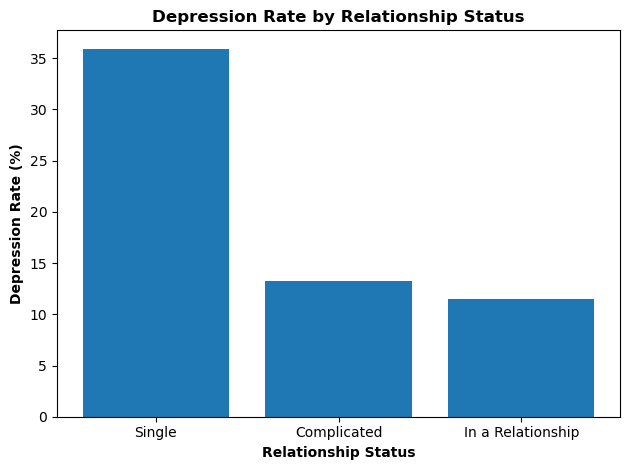

In [4]:
statuses = ["Single", "Complicated", "In a Relationship"]
rates = []

for status in statuses:
    group = df[df["Relationship_status"] == status]
    rate = (len(group[group["Depression"] == "Yes"])) / len(group) * 100
    rates.append(rate)

plt.bar(statuses, rates)

plt.title("Depression Rate by Relationship Status", fontweight="bold")
plt.xlabel("Relationship Status", fontweight="bold")
plt.ylabel("Depression Rate (%)", fontweight="bold")
plt.tight_layout()
plt.show()


In [5]:
print(df.dtypes)

Gender                  object
Age                      int64
Family_background       object
Relationship_status     object
Marital_status          object
Living_style            object
Current_semester         int64
CGPA                   float64
friend_circle           object
Health_condition        object
Cost_without_study       int64
Home_division           object
Depression              object
dtype: object


### Data Source and Collection Method

The dataset, Student Depression Dataset was obtained from https://data.mendeley.com/datasets/xn9cb5zpgg/2

The data was collected through a survey using google forms. The participants were students between the ages of 17-28.


### Data Cleaning

To avoid misleading results, I chose to clean the data by finiding missing or duplicate rows. None were found so no changes happened to the dataset.

### Feature Selection

All 12. available predictor variables were selected because the represent different aspects os students' demographic backgrounds, academic performace, living stituations, and health conditions. The goal is to predict the target variable Depresion, which indicates whether or not a student has depression.

In [6]:
print(df["Depression"].value_counts())

Depression
No     3263
Yes    1201
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

X = df.drop("Depression", axis=1)
y = df["Depression"]

X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [15]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier(random_state=42)

model_tree.fit(X_train, y_train)

y_pred = model_tree.predict(X_test)

In [16]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy", accuracy)

print(classification_report(y_test, y_pred))

Accuracy 0.9966405375139977
              precision    recall  f1-score   support

          No       1.00      1.00      1.00       653
         Yes       1.00      0.99      0.99       240

    accuracy                           1.00       893
   macro avg       1.00      0.99      1.00       893
weighted avg       1.00      1.00      1.00       893



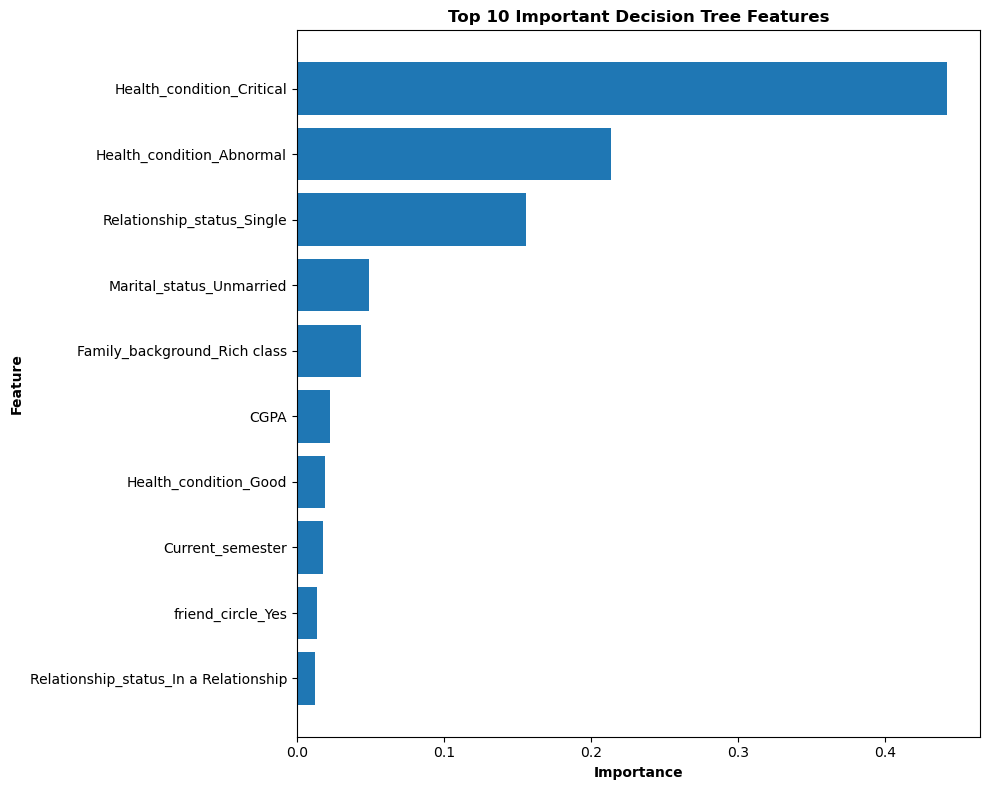

In [56]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_tree.feature_importances_
})

importance = importance.sort_values(by="Importance", ascending=False)

top_10_features = importance.head(10)

plt.figure(figsize=(10,8))

plt.barh(top_10_features["Feature"], top_10_features["Importance"])

plt.title("Top 10 Important Decision Tree Features", fontweight="bold")
plt.xlabel("Importance", fontweight="bold")
plt.ylabel("Feature", fontweight="bold")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [22]:
# Remove Health_condition from the features
X2 = df.drop(["Depression", "Health_condition"], axis=1)
y = df["Depression"]

# Encode categorical features
X2 = pd.get_dummies(X2, drop_first=False)

# Split the data
X2_train, X2_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

# Train a second Decision Tree
model2 = DecisionTreeClassifier(random_state=42)
model2.fit(X2_train, y_train)

# Evaluate the model
y_pred2 = model2.predict(X2_test)

print("Accuracy:", accuracy_score(y_test, y_pred2))
print(classification_report(y_test, y_pred2))

Accuracy: 0.6640537513997761
              precision    recall  f1-score   support

          No       0.78      0.75      0.76       653
         Yes       0.39      0.44      0.41       240

    accuracy                           0.66       893
   macro avg       0.59      0.59      0.59       893
weighted avg       0.68      0.66      0.67       893



In [25]:
from sklearn.naive_bayes import MultinomialNB

model_nb = MultinomialNB()

model_nb.fit(X_train, y_train)

pred_nb = model_nb.predict(X_test)

print("NB Accuracy:", accuracy_score(y_test, pred_nb))
print(classification_report(y_test, pred_nb))

NB Accuracy: 0.9428891377379619
              precision    recall  f1-score   support

          No       0.96      0.96      0.96       653
         Yes       0.89      0.90      0.89       240

    accuracy                           0.94       893
   macro avg       0.93      0.93      0.93       893
weighted avg       0.94      0.94      0.94       893



In [28]:
model_nb_2 = MultinomialNB()

model_nb_2.fit(X2_train, y_train)

pred_nb_2 = model_nb_2.predict(X2_test)

print("NB Accuracy:", accuracy_score(y_test, pred_nb_2))
print(classification_report(y_test, pred_nb_2))

NB Accuracy: 0.7088465845464725
              precision    recall  f1-score   support

          No       0.76      0.88      0.82       653
         Yes       0.43      0.25      0.31       240

    accuracy                           0.71       893
   macro avg       0.59      0.56      0.56       893
weighted avg       0.67      0.71      0.68       893



In [34]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Decision Tree (Without Heallth Condition)",
        "Naive Bayes",
        "Naive Bayes (Without Health Condition)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred2),
        accuracy_score(y_test, pred_nb),
        accuracy_score(y_test, pred_nb_2)
    ]
})

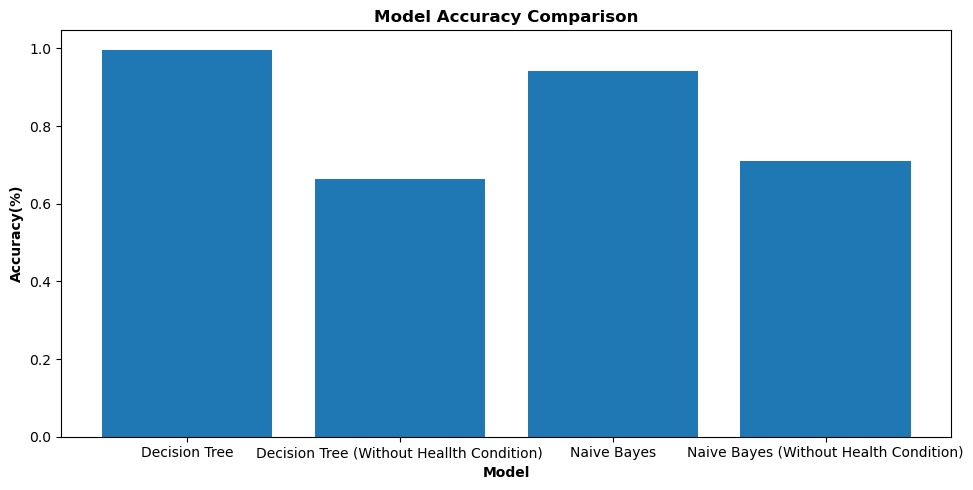

In [36]:
plt.figure(figsize=(10,5))
plt.bar(results["Model"], results["Accuracy"])

plt.title("Model Accuracy Comparison", fontweight="bold")
plt.xlabel("Model", fontweight="bold")
plt.ylabel("Accuracy(%)", fontweight="bold")
plt.tight_layout()
plt.show()

In [41]:
from sklearn.metrics import precision_score, recall_score, f1_score

model_predictions = [y_pred, y_pred2, pred_nb, pred_nb_2]

performance = []

for prediction in model_predictions:
    performance.append({
        "accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction, pos_label="Yes"),
        "Recall": recall_score(y_test, prediction, pos_label="Yes"),
        "F1-score": f1_score(y_test, prediction, pos_label="Yes")
    })

performance_df = pd.DataFrame(performance, index=results["Model"])
display(performance_df.round(3))

,accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree,0.997,1.000,0.988,0.994
Decision Tree (Without Heallth Condition),0.664,0.390,0.442,0.414
Naive Bayes,0.943,0.892,0.896,0.894
Naive Bayes (Without Health Condition),0.709,0.428,0.246,0.312


In [44]:
depth = 3

model_depthlimit = DecisionTreeClassifier(max_depth=depth)

model_depthlimit.fit(X_train, y_train)

pred_depthlimit = model_depthlimit.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_depthlimit))
print(classification_report(y_test, pred_depthlimit))


Accuracy: 0.9596864501679732
              precision    recall  f1-score   support

          No       0.97      0.97      0.97       653
         Yes       0.93      0.93      0.93       240

    accuracy                           0.96       893
   macro avg       0.95      0.95      0.95       893
weighted avg       0.96      0.96      0.96       893



In [45]:
split_samples = 20

model_depthlimit = DecisionTreeClassifier(min_samples_split = split_samples)

model_depthlimit.fit(X_train, y_train)

pred_depthlimit = model_depthlimit.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred_depthlimit))
print(classification_report(y_test, pred_depthlimit))


Accuracy: 0.9888017917133258
              precision    recall  f1-score   support

          No       0.99      0.99      0.99       653
         Yes       0.98      0.98      0.98       240

    accuracy                           0.99       893
   macro avg       0.98      0.99      0.99       893
weighted avg       0.99      0.99      0.99       893

